# 03 — Exploratory Analysis: residential broadband access in Vermont

FCC BDC fixed availability, data as of Dec 31, 2025. Universe: locations with at least one residential (`R`) or mixed (`X`) offer.

**Definitions** (see `docs/methodology.md`):
* *Reliable technology* (NTIA BEAD): fiber, cable, copper/DSL, licensed and LBR fixed wireless. Satellite and unlicensed fixed wireless are excluded.
* *Served* ≥ 100/20 Mbps reliable + low latency · *Underserved* ≥ 25/3 but < 100/20 · *Unserved* < 25/3.
* *Wired 100/20 competition*: number of distinct providers offering ≥ 100/20 over fiber, cable or copper.

All figures describe **reported availability**, not adoption, price or measured performance.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve() / "src"))  # not needed when installed with `uv sync`

import pandas as pd
import matplotlib.pyplot as plt
from vermont_broadband_analysis import config

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
ANALYSIS = config.PROCESSED_DIR / "analysis"
plt.rcParams.update({
    "font.family": "sans-serif", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781", "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
BLUE, BLUE_DARK, BLUE_LIGHT = "#2a78d6", "#104281", "#86b6ef"

In [2]:
from vermont_broadband_analysis import metrics

tables = metrics.run()
loc = tables["location_access"]

Location table: 282,377 residential locations
                                       0
locations                      282377.00
served                         253307.00
underserved                     15158.00
unserved                        13912.00
has_fiber                      183350.00
has_cable                      190102.00
has_copper                     104779.00
has_fixed_wireless             260209.00
has_gigabit_wired              250006.00
satellite_only                   3085.00
no_wired_100_20                 30814.00
one_wired_100_20               119777.00
two_plus_wired_100_20          131786.00
median_best_reliable_download    2000.00
pct_served                         89.71
pct_underserved                     5.37
pct_unserved                        4.93
pct_has_fiber                      64.93
pct_has_cable                      67.32
pct_has_copper                     37.11
pct_has_fixed_wireless             92.15
pct_has_gigabit_wired              88.54
pct_satelli

## 1. Statewide service tiers

In [3]:
tiers = tables["service_tier_distribution"].set_index("service_tier").loc[["served", "underserved", "unserved"]]
tiers["pct"] = (tiers["locations"] / tiers["locations"].sum() * 100).round(1)
tiers

,locations,pct
service_tier,,
served,253307,89.7
underserved,15158,5.4
unserved,13912,4.9


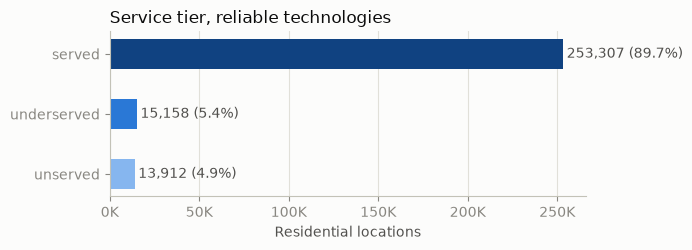

In [4]:
fig, ax = plt.subplots(figsize=(7, 2.6))
colors = [BLUE_DARK, BLUE, BLUE_LIGHT]
ax.barh(tiers.index[::-1], tiers["locations"][::-1], color=colors[::-1], height=0.5)
for i, (n, p) in enumerate(zip(tiers["locations"][::-1], tiers["pct"][::-1])):
    ax.text(n + 2000, i, f"{n:,.0f} ({p}%)", va="center", color="#52514e")
ax.set_xlabel("Residential locations"); ax.set_title("Service tier, reliable technologies", loc="left")
ax.xaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}K"); ax.grid(axis="y", visible=False)
plt.tight_layout()

## 2. Technology footprint

In [5]:
tables["technology_summary"]

,technology,technology_name,records,locations,providers,median_download,median_upload,pct_of_locations,reliable_under_bead
3,60,GSO Satellite,564703,282371,2,100.0,3.0,100.00,False
4,61,NGSO Satellite,282226,282226,1,280.0,30.0,99.95,False
6,71,Licensed Fixed Wireless,498967,258895,5,25.0,3.0,91.68,True
1,40,Cable,190135,190102,4,1200.0,35.0,67.32,True
2,50,Fiber to the Premises,199013,183350,20,2000.0,2000.0,64.93,True
0,10,Copper,104869,104779,8,10.0,1.0,37.11,True
5,70,Unlicensed Fixed Wireless,9014,9009,4,75.0,25.0,3.19,False
7,72,LBR Fixed Wireless,7989,7981,5,50.0,10.0,2.83,True


Satellite reaches essentially every location, and licensed fixed wireless reaches 92%. Licensed FW's median advertised download is only 25 Mbps, though,
and GSO satellite is high-latency. Fiber (65%) and cable (67%) carry the high-speed tiers.

## 3. Wired competition at 100/20

In [6]:
comp = tables["competition_distribution"]
comp["pct"] = (comp["locations"] / comp["locations"].sum() * 100).round(1)
comp

,wired_100_20_providers,locations,pct
0,0,30814,10.9
1,1,119777,42.4
2,2,126775,44.9
3,3,5006,1.8
4,4,5,0.0


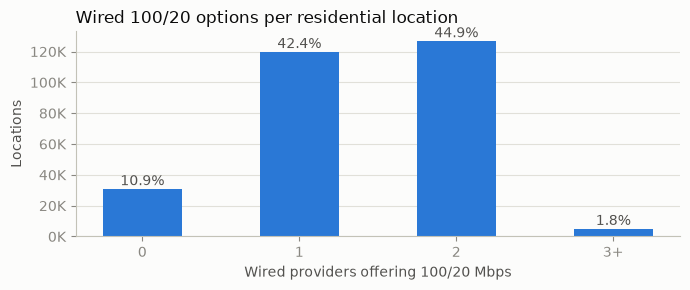

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
labels = ["0", "1", "2", "3+"]
vals = [comp.loc[comp.wired_100_20_providers == 0, "locations"].sum(), comp.loc[comp.wired_100_20_providers == 1, "locations"].sum(),
        comp.loc[comp.wired_100_20_providers == 2, "locations"].sum(), comp.loc[comp.wired_100_20_providers >= 3, "locations"].sum()]
ax.bar(labels, vals, color=BLUE, width=0.5)
for i, v in enumerate(vals):
    ax.text(i, v + 2500, f"{v/sum(vals)*100:.1f}%", ha="center", color="#52514e")
ax.set_xlabel("Wired providers offering 100/20 Mbps"); ax.set_ylabel("Locations")
ax.yaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}K"); ax.grid(axis="x", visible=False)
ax.set_title("Wired 100/20 options per residential location", loc="left"); plt.tight_layout()

## 4. Counties

In [8]:
county = tables["county_summary"].sort_values("pct_served")
county[["county_name", "locations", "pct_served", "pct_underserved", "pct_unserved", "pct_has_fiber",
        "pct_no_wired_100_20", "pct_two_plus_wired_100_20", "satellite_only"]]

,county_name,locations,pct_served,pct_underserved,pct_unserved,pct_has_fiber,pct_no_wired_100_20,pct_two_plus_wired_100_20,satellite_only
4,Essex,4676,55.30,26.65,18.05,36.40,47.86,15.78,209
6,Grand Isle,5590,60.72,29.37,9.91,0.02,40.86,0.02,132
9,Orleans,15412,67.80,16.27,15.93,20.77,33.10,12.63,255
2,Caledonia,14875,74.45,13.39,12.15,44.67,26.61,28.01,394
5,Franklin,20951,87.38,8.09,4.53,46.22,13.34,29.83,331
8,Orange,14534,87.86,6.36,5.79,79.24,13.55,30.76,137
11,Washington,25141,88.36,5.42,6.22,66.54,12.78,45.48,325
0,Addison,16559,88.44,4.56,7.01,67.69,12.30,38.52,210
12,Windham,24617,88.93,5.30,5.77,57.59,11.91,32.43,291
7,Lamoille,12601,92.74,3.00,4.26,84.93,7.31,53.12,130


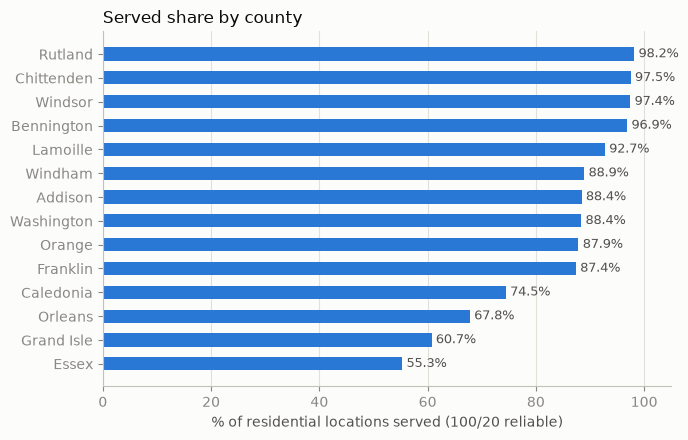

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(county["county_name"], county["pct_served"], color=BLUE, height=0.55)
for i, v in enumerate(county["pct_served"]):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", color="#52514e", fontsize=9)
ax.set_xlim(0, 105); ax.set_xlabel("% of residential locations served (100/20 reliable)")
ax.set_title("Served share by county", loc="left"); ax.grid(axis="y", visible=False); plt.tight_layout()

## 5. Providers
The `sole_wired_100_20_locations` column counts locations where this provider is the **only** wired 100/20 option.

In [10]:
tables["provider_summary"].head(15)

,provider_id,brand_name,locations,technologies,median_download,sole_wired_100_20_locations
21,290111,Viasat Inc,282363,GSO Satellite,50.0,0
9,130627,HughesNet,282340,GSO Satellite,100.0,0
26,430076,Starlink,282226,NGSO Satellite,280.0,0
32,460632,VTel Wireless Inc,247300,Licensed Fixed Wireless,25.0,0
4,130317,Xfinity,171306,"Cable, Fiber to the Premises",1200.0,61314
7,130403,T-Mobile,139685,Licensed Fixed Wireless,0.0,0
5,130335,Consolidated Communications,97204,Copper,10.0,168
6,130335,Fidium Fiber,91417,Fiber to the Premises,2000.0,14246
15,131425,Verizon,58109,Licensed Fixed Wireless,25.0,0
0,130077,AT&T,53290,Licensed Fixed Wireless,25.0,0


## 6. Least-served census tracts

In [11]:
tables["tract_summary"].query("locations >= 100").nsmallest(10, "pct_served")[
    ["tract_geoid", "county_name", "locations", "pct_served", "pct_unserved", "pct_has_fiber", "satellite_only"]]

,tract_geoid,county_name,locations,pct_served,pct_unserved,pct_has_fiber,satellite_only
73,50009950100,Essex,1658,23.22,32.63,17.85,152
87,50013020100,Grand Isle,3158,32.58,17.07,0.00,128
112,50019951700,Orleans,2288,35.53,33.83,27.75,69
97,50017959101,Orange,1096,43.80,19.53,13.05,35
22,50005957000,Caledonia,2607,46.30,23.82,37.17,62
106,50019951100,Orleans,1793,48.13,37.59,0.00,82
136,50023954000,Washington,2031,52.68,28.02,20.24,58
79,50011010300,Franklin,1781,53.45,20.10,2.58,74
30,50005957800,Caledonia,1800,61.00,29.89,45.72,169
80,50011010400,Franklin,1488,61.49,15.46,53.90,88


## 7. Takeaways
* **89.7%** of residential locations are served at 100/20 by a reliable technology; **4.9%** (13,912) are unserved and **5.4%** underserved.
* Wired gigabit availability is broad (**88.5%**), driven by fiber (65%) and cable (67%).
* Competition is thin: **42.4%** of locations have exactly one wired 100/20 provider, and **10.9%** have none.
* Gaps concentrate in the Northeast Kingdom (Essex, Orleans, Caledonia) and Grand Isle; Rutland, Windsor, Chittenden and Bennington are near-universal.
* 3,085 locations (1.1%) rely on satellite only.